# 🚀 Practice Day 66

**📅 Date:** 2026-11-06  
📁 Category: Phase 3 · 엔드투엔드 미니 파이프라인 (Round 5/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Run a full mini pipeline end to end — clean two messy tables, merge them, then analyze and visualize the result
  (지저분한 테이블 2개를 정제하고 병합한 뒤 분석·시각화까지 전체 파이프라인을 한 번에 진행하기)
- Find which specialty earns the most, what the average repair cost is, and which technician handles the most orders
  (어떤 전문분야가 매출을 가장 많이 내는지, 평균 수리비용은 얼마인지, 어떤 기사가 가장 많은 주문을 처리하는지 파악하기)

---
# 📂 Dataset

**Dataset Name:** FixRight Appliance Repair — Technicians & Repair Orders (2 tables) / FixRight 가전 수리 — 기사·수리주문 (2테이블)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** Two messy tables. `technicians` (12 rows: technician_id, specialty) has inconsistent capitalization/whitespace in `specialty`, plus one missing value. `repair_orders` (~312 rows: order_id, technician_id → links to technicians, order_date, cost) has missing cost, missing order_date, and some exact duplicate rows. The core of this file is cleaning both tables, then merging them for analysis.
(지저분한 테이블 2개입니다. `technicians`(12명: technician_id, specialty)는 specialty 표기가 대소문자·공백 등으로 일관되지 않고 1건은 결측치입니다. `repair_orders`(약 312건: order_id, technician_id(technicians와 연결), order_date, cost)는 cost 결측, order_date 결측, 완전 중복행을 포함합니다. 두 테이블을 각각 정제한 뒤 병합해서 분석하는 것이 이 파일의 핵심입니다.)

## Dataset Preview

In [47]:
# Dataset Preview
import pandas as pd
import numpy as np
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)

# --- technicians (messy: inconsistent specialty text, one missing) ---
specialties = ['HVAC', 'Refrigerator', 'Washer-Dryer', 'Electronics']
rate_base = {'HVAC': 180, 'Refrigerator': 130, 'Washer-Dryer': 95, 'Electronics': 75}  # USD per repair order
spec_w = [0.28, 0.24, 0.26, 0.22]

n_tech = 12
tech_spec_assign = rng.choice(specialties, size=n_tech, p=spec_w)
technicians = pd.DataFrame({
    'technician_id': [f'T{str(i).zfill(3)}' for i in range(1, n_tech + 1)],
    'specialty': tech_spec_assign
})
technicians['specialty'] = technicians['specialty'].astype(object)

mess_idx = rng.choice(technicians.index, size=int(n_tech * 0.4), replace=False)
for i in mess_idx:
    base = technicians.loc[i, 'specialty']
    technicians.loc[i, 'specialty'] = rng.choice([base.lower(), base.upper(), ' ' + base, base + ' '])

miss_idx = rng.choice(technicians.index, size=1, replace=False)
technicians.loc[miss_idx, 'specialty'] = np.nan

# --- repair_orders (messy: missing cost, missing order_date, duplicate rows) ---
n_orders = 300
clean_spec_map = dict(zip(technicians['technician_id'], tech_spec_assign))
tech_choice = rng.choice(technicians['technician_id'].values, size=n_orders, replace=True)
order_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 200, size=n_orders), unit='D')

rows = []
for i in range(n_orders):
    tid = tech_choice[i]
    spec = clean_spec_map[tid]
    noise = rng.normal(1.0, 0.09)
    cost = int(round(rate_base[spec] * noise, 0))
    rows.append({'order_id': f'RO{str(i+1).zfill(4)}', 'technician_id': tid, 'order_date': order_dates[i], 'cost': cost})
repair_orders = pd.DataFrame(rows)

miss_cost_idx = rng.choice(repair_orders.index, size=13, replace=False)
repair_orders.loc[miss_cost_idx, 'cost'] = np.nan

avail_idx = repair_orders.index.difference(miss_cost_idx)
miss_date_idx = rng.choice(avail_idx, size=8, replace=False)
repair_orders.loc[miss_date_idx, 'order_date'] = pd.NaT

dupe_rows = repair_orders.sample(n=12, random_state=7)
repair_orders = pd.concat([repair_orders, dupe_rows], ignore_index=True)
repair_orders = repair_orders.sample(frac=1, random_state=99).reset_index(drop=True)

print("Technicians:")
display(technicians)
print("\nRepair Orders:")
display(repair_orders.head())


Technicians:


,technician_id,specialty
0,T001,NaN
1,T002,Refrigerator
2,T003,Electronics
3,T004,Washer-Dryer
4,T005,HVAC
5,T006,Electronics
6,T007,Washer-Dryer
7,T008,electronics
8,T009,HVAC
9,T010,refrigerator



Repair Orders:


,order_id,technician_id,order_date,cost
0,RO0200,T009,2024-01-31,171.0
1,RO0114,T001,2024-02-27,107.0
2,RO0274,T002,2024-06-20,134.0
3,RO0082,T002,2024-01-25,136.0
4,RO0003,T004,2024-02-10,100.0


## Dataset Information

In [48]:
# Dataset Information
print("Technicians:", technicians.shape)
technicians.info()
print("\nRepair Orders:", repair_orders.shape)
repair_orders.info()

print("\n--- Describe: Technicians ---")
display(technicians.describe(include='all'))
print("\n--- Describe: Repair Orders ---")
display(repair_orders.describe(include='all'))


Technicians: (12, 2)
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   technician_id  12 non-null     str   
 1   specialty      11 non-null     object
dtypes: object(1), str(1)
memory usage: 324.0+ bytes

Repair Orders: (312, 4)
<class 'pandas.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       312 non-null    str           
 1   technician_id  312 non-null    str           
 2   order_date     304 non-null    datetime64[us]
 3   cost           297 non-null    float64       
dtypes: datetime64[us](1), float64(1), str(2)
memory usage: 9.9 KB

--- Describe: Technicians ---


,technician_id,specialty
count,12,11
unique,12,8
top,T001,Electronics
freq,1,3



--- Describe: Repair Orders ---


,order_id,technician_id,order_date,cost
count,312,312,304,297.000000
unique,300,12,NaN,NaN
top,RO0082,T006,NaN,NaN
freq,2,39,NaN,NaN
mean,NaN,NaN,2024-04-10 03:00:00,111.427609
min,NaN,NaN,2024-01-02 00:00:00,55.000000
25%,NaN,NaN,2024-02-17 00:00:00,79.000000
50%,NaN,NaN,2024-04-10 00:00:00,101.000000
75%,NaN,NaN,2024-06-05 12:00:00,135.000000
max,NaN,NaN,2024-07-18 00:00:00,214.000000


---
# ❓ Business Questions

1. **(Analysis)** After cleaning and merging, which specialty generated the most total repair revenue, and which the least?
   (정제·병합 후, 어떤 전문분야가 가장 많은/적은 수리매출을 냈는가?)
2. **(Analysis)** What is the average cost per repair order?
   (주문당 평균 수리비용은?)
3. **(Analysis)** Which specific technician has handled the most repair orders, and how many?
   (가장 많은 수리주문을 처리한 기사는 누구이며, 몇 건인가?)
4. **(Visualization)** Compare total revenue across all specialties.
   (전문분야별 총매출을 비교하면?)
5. **(Visualization)** Show how the number of repair orders moves month to month.
   (월별 수리주문 건수는 어떻게 변화하는가?)

---
# 🔍 Data Cleaning Check


In [49]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("===== technicians =====")
print("Missing values")
print(technicians.isnull().sum())
print("\nDuplicate rows:", technicians.duplicated().sum())
print("\nDtypes")
print(technicians.dtypes)
print("\nColumn names")
print(technicians.columns.tolist())
obj_cols = technicians.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(technicians[obj_cols].nunique())
print()

print("===== repair_orders =====")
print("Missing values")
print(repair_orders.isnull().sum())
print("\nDuplicate rows:", repair_orders.duplicated().sum())
print("\nDtypes")
print(repair_orders.dtypes)
print("\nColumn names")
print(repair_orders.columns.tolist())
obj_cols = repair_orders.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(repair_orders[obj_cols].nunique())
print()


===== technicians =====
Missing values
technician_id    0
specialty        1
dtype: int64

Duplicate rows: 0

Dtypes
technician_id       str
specialty        object
dtype: object

Column names
['technician_id', 'specialty']

Text columns — unique counts
technician_id    12
specialty         8
dtype: int64

===== repair_orders =====
Missing values
order_id          0
technician_id     0
order_date        8
cost             15
dtype: int64

Duplicate rows: 12

Dtypes
order_id                    str
technician_id               str
order_date       datetime64[us]
cost                    float64
dtype: object

Column names
['order_id', 'technician_id', 'order_date', 'cost']

Text columns — unique counts
order_id         300
technician_id     12
dtype: int64



---
# 📊 Analysis

## Question 1

**Question:** After cleaning and merging, which specialty generated the most total repair revenue, and which the least? (정제·병합 후 최고·최저 매출 전문분야는?)

**Result:** Refrigerator generated the most revenue at **$10,228**. Washer-Dryer generated the least at **$4,931**. The gap is **$5,297**.  
(매출 1위는 Refrigerator $10,228, 맨 아래는 Washer-Dryer $4,931. 차이는 $5,297)

**Insight:** HVAC is next at **$7,933**, which is **$2,295** below Refrigerator. Technician T001 (**19** orders) has no specialty, so those orders are not in these sums.  
(다음은 HVAC $7,933으로 Refrigerator보다 $2,295 적음. 기사 T001(주문 **19**건)은 전문분야가 없어 이 합계에 들어가지 않음)

In [50]:
# Question 1: total revenue by specialty (after cleaning + merging)
cleaned_technicians = technicians.copy()

print(technicians['specialty'].unique())

cleaned_technicians['specialty'] = cleaned_technicians['specialty'].str.strip().str.title().replace({'Hvac': 'HVAC'})

cleaned_technicians['specialty'].unique()

[nan 'Refrigerator' 'Electronics' 'Washer-Dryer' np.str_('HVAC ')
 np.str_(' Washer-Dryer') np.str_('electronics') 'HVAC'
 np.str_('refrigerator')]


array([nan, 'Refrigerator', 'Electronics', 'Washer-Dryer', 'HVAC'],
      dtype=object)

In [51]:
cleaned_repair_orders = repair_orders.copy()

print(repair_orders.duplicated().sum(), repair_orders.shape[0])

cleaned_repair_orders.drop_duplicates(inplace=True)

print(cleaned_repair_orders.duplicated().sum(), cleaned_repair_orders.shape[0])

12 312
0 300


In [52]:
merged_df = pd.merge(cleaned_repair_orders, cleaned_technicians, on='technician_id', how='left')

total_cost_by_specialty = merged_df.groupby('specialty')['cost'].sum().sort_values(ascending=False)

total_cost_by_specialty

specialty
Refrigerator    10228.0
HVAC             7933.0
Electronics      6972.0
Washer-Dryer     4931.0
Name: cost, dtype: float64

## Question 2

**Question:** What is the average cost per repair order? (주문당 평균 수리비용은?)

**Result:** The average repair order costs **$110.99**.  
(주문당 평균 수리비용은 $110.99)

**Insight:** This is the mean of **287** orders that have a cost, after the **12** exact duplicates were removed (**300** orders). The missing costs are skipped by `.mean()`.  
(정확히 같은 중복 12건을 지운 뒤(주문 **300**건) 비용이 있는 **287**건의 평균. 비어 있는 비용은 `.mean()`이 건너뜀)

In [53]:
# Question 2: average cost per repair order across all orders
print(merged_df['cost'].mean())
print(merged_df['cost'].count())


110.98606271777004
287


## Question 3

**Question:** Which specific technician has handled the most repair orders, and how many? (가장 많은 주문을 처리한 기사와 건수는?)

**Result:** Technician **T006** (Electronics) handled the most orders, **38**.  
(가장 많은 주문을 처리한 기사는 T006(Electronics), **38**건)

**Insight:** T010 (Refrigerator) follows at **35**, which is **3** below T006. T011 (Refrigerator) is lowest at **15**.  
(T010(Refrigerator)이 **35**건으로 T006보다 **3**건 적음. T011(Refrigerator)이 **15**건으로 가장 적음)

In [54]:
# Question 3: most-active technician (by order count)
merged_df.groupby(['technician_id', 'specialty'], dropna=False)['order_id'].count().sort_values(ascending=False)

technician_id  specialty   
T006           Electronics     38
T010           Refrigerator    35
T002           Refrigerator    31
T004           Washer-Dryer    30
T009           HVAC            27
T007           Washer-Dryer    24
T008           Electronics     23
T005           HVAC            20
T001           NaN             19
T003           Electronics     19
T012           Electronics     19
T011           Refrigerator    15
Name: order_id, dtype: int64

---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by specialty (막대그래프: 전문분야별 총매출)

*Interpretation:* The bars follow the revenue table: Refrigerator **$10,228**, HVAC **$7,933**, Electronics **$6,972**, Washer-Dryer **$4,931**.  
(막대는 매출 표 순서. Refrigerator $10,228, HVAC $7,933, Electronics $6,972, Washer-Dryer $4,931)

---

**Chart 2:** Line chart — monthly repair order count (선그래프: 월별 수리주문 건수 추이)

*Interpretation:* Orders start at about **51** in January and fall to about **36** in May. June rises to about **47**, and July is the lowest at about **33**.  
(주문은 1월 약 **51**건에서 5월 약 **36**건까지 내려갑니다. 6월은 약 **47**건으로 오르고, 7월이 약 **33**건으로 가장 낮음)

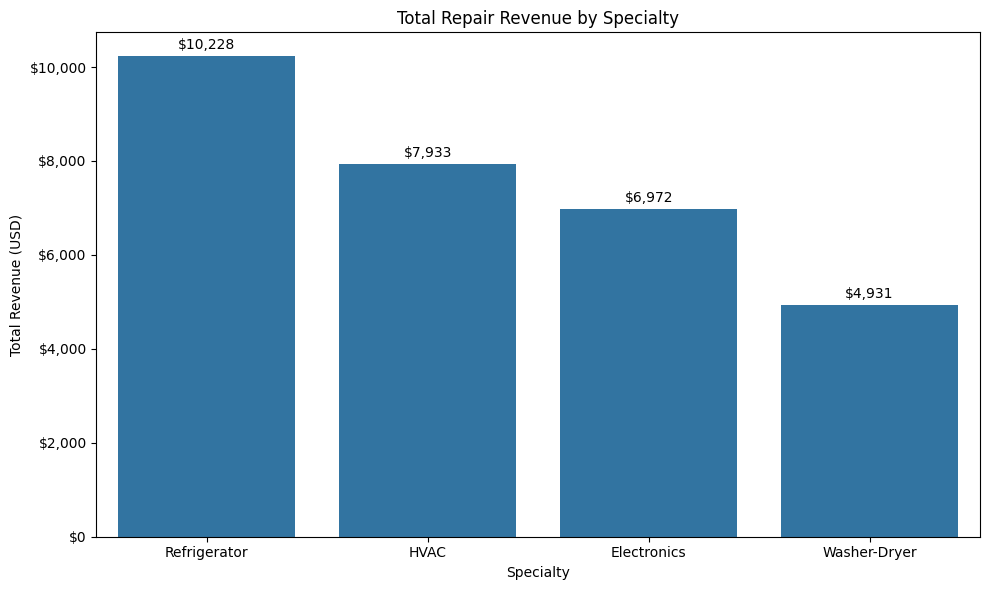

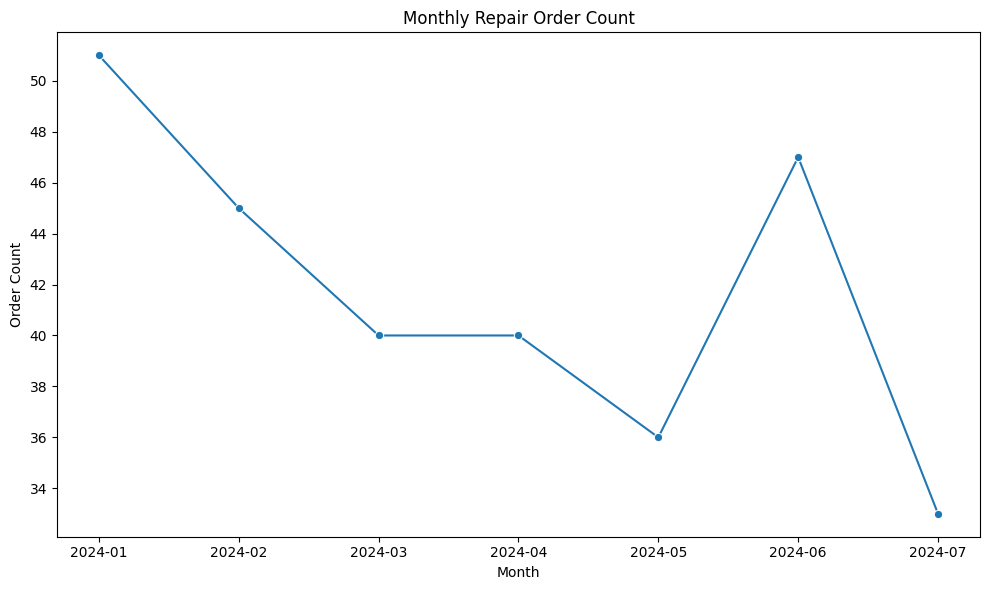

In [55]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

# Chart 1: total revenue by specialty (bar)
# Same order as the Q1 table (orders with a missing specialty or cost are not in the sum)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=total_cost_by_specialty.index, y=total_cost_by_specialty.values, errorbar=None, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='${:,.0f}', padding=3)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Total Repair Revenue by Specialty')
ax.set_xlabel('Specialty')
ax.set_ylabel('Total Revenue (USD)')
plt.tight_layout()
plt.show()

# Chart 2: monthly repair order count (line)
# Orders with a missing order_date are left out of the monthly count
monthly_order = merged_df.groupby(merged_df['order_date'].dt.to_period('M'))['order_id'].count()

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x=monthly_order.index.astype(str), y=monthly_order.values, marker='o', ax=ax)
ax.set_title('Monthly Repair Order Count')
ax.set_xlabel('Month')
ax.set_ylabel('Order Count')
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Refrigerator earns the most at **$10,228**, and Washer-Dryer the least at **$4,931**.  
  (Refrigerator가 $10,228로 매출 1위, Washer-Dryer는 $4,931로 맨 아래)
- The average order costs **$110.99**, and T006 handled the most orders at **38**.  
  (주문당 평균 비용은 $110.99, 가장 많이 처리한 기사는 T006으로 **38**건)
- Monthly orders fall from about **51** in January to about **33** in July, with a bump to about **47** in June.  
  (월별 주문은 1월 약 **51**건에서 7월 약 **33**건으로 줄고, 6월에 약 **47**건으로 잠깐 오름)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Treat Refrigerator as the revenue leader. Its **$10,228** is **$5,297** above Washer-Dryer.  
   (Refrigerator를 매출 중심으로 볼 것. $10,228은 Washer-Dryer보다 $5,297 많음)
2. Fill in the specialty for T001 (**19** orders) before the next revenue report.  
   (다음 매출 보고 전에 T001(주문 **19**건)의 전문분야를 채워 둘 것)
3. Look into the drop from about **51** orders in January to about **33** in July.  
   (1월 약 **51**건에서 7월 약 **33**건으로 내려간 구간을 살펴볼 것)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- `.str.title()` turned `HVAC` into `Hvac`, so I mapped it back to `HVAC`.  
  (`.str.title()`가 `HVAC`를 `Hvac`로 바꿔서 `HVAC`로 되돌렸음)
- The charts had no title, axis titles, or `$` labels at first.  
  (처음에는 차트에 제목, 축 제목, `$` 표시가 없었음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `.str.strip().str.title()` turns the **8** spellings of `specialty` into four names, and an acronym like `HVAC` needs its own fix.  
  (`.str.strip().str.title()`로 `specialty` 표기 **8**개가 네 이름으로 정리되고, `HVAC` 같은 약어는 따로 고쳐야 함)
- `drop_duplicates()` before `merge(..., how='left')` keeps **300** orders.  
  (`drop_duplicates()` 뒤에 `merge(..., how='left')`하면 주문 **300**건이 그대로 유지됨)
- `groupby(..., dropna=False)` keeps technician T001, whose specialty is missing.  
  (`groupby(..., dropna=False)`는 전문분야가 없는 기사 T001을 유지함)  

---
# 🧠 Reflection

**What was difficult?**  
Showing the technician's name next to the order count.  
(기사 이름을 주문 건수 옆에 보여주는 것)

**Why?**  
The `technicians` table has only `technician_id` and `specialty`, so there is no name column.  
(`technicians` 표에는 `technician_id`와 `specialty`만 있어서 이름 열이 없음)

**How did I solve it?**  
Grouped by `technician_id` and `specialty` together, with `dropna=False`.  
(`technician_id`와 `specialty`로 같이 묶고 `dropna=False`를 씀)

**What would I do differently next time?**  
Check which columns each table has before planning the output.  
(결과를 정하기 전에 각 표에 어떤 열이 있는지 먼저 확인하기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The cleaning, the merge, and the three groupbys match the questions. Refrigerator earns **$10,228** and T006 handled **38** orders.  
(정제, 병합, groupby 세 개가 질문과 맞음. Refrigerator 매출 $10,228, T006은 **38**건)  

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  
The pipeline steps were short. The `HVAC` spelling and the chart labels took the extra work.  
(파이프라인 단계는 짧았음. `HVAC` 표기와 차트 라벨에 손이 더 갔음)  

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- 66개 파일 시리즈 완주! 🎉